# Acoustic FWI parametrized in velocity

## Author: M. Alfarhan

This notebook reproduce the results of the paper "A Foundation Model-Based Objective Function for Full Waveform Inversion" for the Marmousi example

In [ ]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import os
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from contextlib import redirect_stdout, redirect_stderr

from scipy.ndimage import gaussian_filter
from scipy.optimize import minimize
from devito import configuration
from pylops.basicoperators import Diagonal, Identity

from devitofwi.waveengine.acoustic import AcousticWave2D
from devitofwi.preproc.masking import TimeSpaceMasking
from devitofwi.postproc.acoustic import create_mask_value, PostProcessVP

import torch
from fm_fwi.model.pretrained import load_pretrained_multidim_wav2vec2

from fm_fwi.losses import SeisLMFeatureLoss, L2, HybridLoss
from fm_fwi.tee import Tee

configuration['log-level'] = 'ERROR'


In [ ]:
from fm_fwi.plotting import plot_velmodel, plot_shotgathers, plot_curve, apply_plot_style

apply_plot_style()

In [3]:
lossfn = 'l2' #'l2' # 'feature', 'hybrid'

## Parameters 

In [4]:
# Model and aquisition parameters (in km, s, and Hz units)
par = {'nx':601,   'dx':0.015,    'ox':0,
       'nz':221,   'dz':0.015,    'oz':0,
       'ns':30,    'ds':0.300,    'os':0.,  'sz':0,
       'nr':300,   'dr':0.030,    'or':0,   'rz':0,
       'nt':3000,  'dt':0.002, 'ot':0,
       'freq':7,
      }

# Modelling parameters
shape = (par['nx'], par['nz'])
spacing = (par['dx'], par['dz'])
origin = (par['ox'], par['oz'])
space_order = 4
nbl = 20

# Velocity model
path = '../data/'
velocity_file = path + 'Marm.bin'

# Time-space mask parameters
vwater = 1.5
toff = 0.35

In [5]:
sm1, sm2 = 60, 40

exp_name = f'test_marmousi_{lossfn}_sm_{sm1}_{sm2}_freq_{par["freq"]}Hz'
if not os.path.exists(exp_name):
    os.mkdir(exp_name)

## Acquisition set-up

In [6]:
# Axes
x = np.arange(par['nx']) * par['dx'] + par['ox']
z = np.arange(par['nz']) * par['dz'] + par['oz']
t = np.arange(par['nt']) * par['dt'] + par['ot']
tmax = t[-1]

# Sources
x_s = np.zeros((par['ns'], 2))
x_s[:, 0] = np.arange(par['ns']) * par['ds'] + par['os']
x_s[:, 1] = par['sz']

# Receivers
x_r = np.zeros((par['nr'], 2))
x_r[:, 0] = np.arange(par['nr']) * par['dr'] + par['or']
x_r[:, 1] = par['rz']

## Velocity model

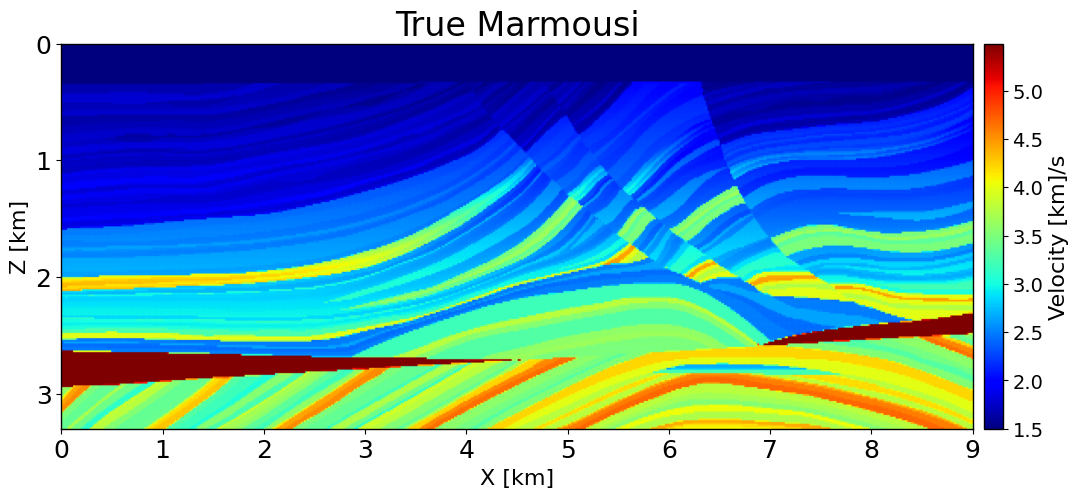

saved test_marmousi_l2_sm_60_40_freq_7Hz/marmousi_true.png


In [7]:
# Load the true model
vp_true = np.fromfile(velocity_file, np.float32).reshape(par['nz'], par['nx']).T
msk = create_mask_value(vp_true, 1.52) # get the mask for the water layer 

vmin, vmax = np.percentile(vp_true, [2, 98])
plot_velmodel(vp_true, "True Marmousi", f"{exp_name}/marmousi_true.png",
              x, z, vmin=vmin, vmax=vmax)

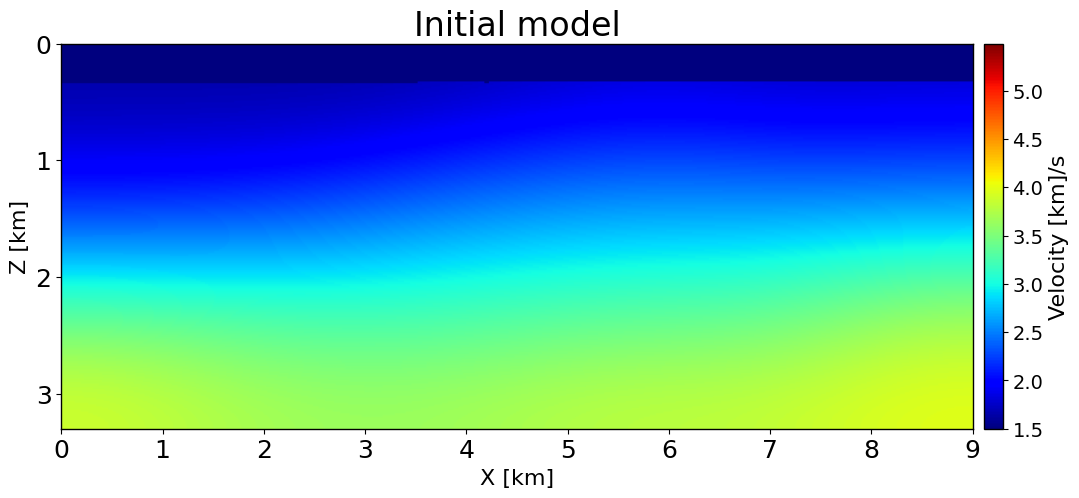

saved test_marmousi_l2_sm_60_40_freq_7Hz/marmousi_init.png


In [8]:
# Initial model for FWI by smoothing the true model
vp_init = gaussian_filter(vp_true, sigma=[sm1,sm2]) # [15, 10]
vp_init = vp_init * msk  # to preserve the water layer  
vp_init[vp_init == 0] = 1.5

plot_velmodel(vp_init, "Initial model", f"{exp_name}/marmousi_init.png",
              x, z, vmin=vmin, vmax=vmax)

## Data modelling

In [9]:
# Define modelling engine
amod = AcousticWave2D(shape, origin, spacing, 
                      x_s[:, 0], x_s[:, 1], x_r[:, 0], x_r[:, 1], 
                      0., tmax,  
                      vp=vp_true, 
                      src_type="Ricker", 
                      f0=par['freq'],
                      space_order=space_order, nbl=nbl,
                      clearcache=False)

# Create model and geometry to extract useful information to define the filtering object
model, geometry = amod.model_and_geometry()

In [10]:
# Model data
dobs, dtobs = amod.mod_allshots()

100%|██████████| 30/30 [00:32<00:00,  1.08s/it]


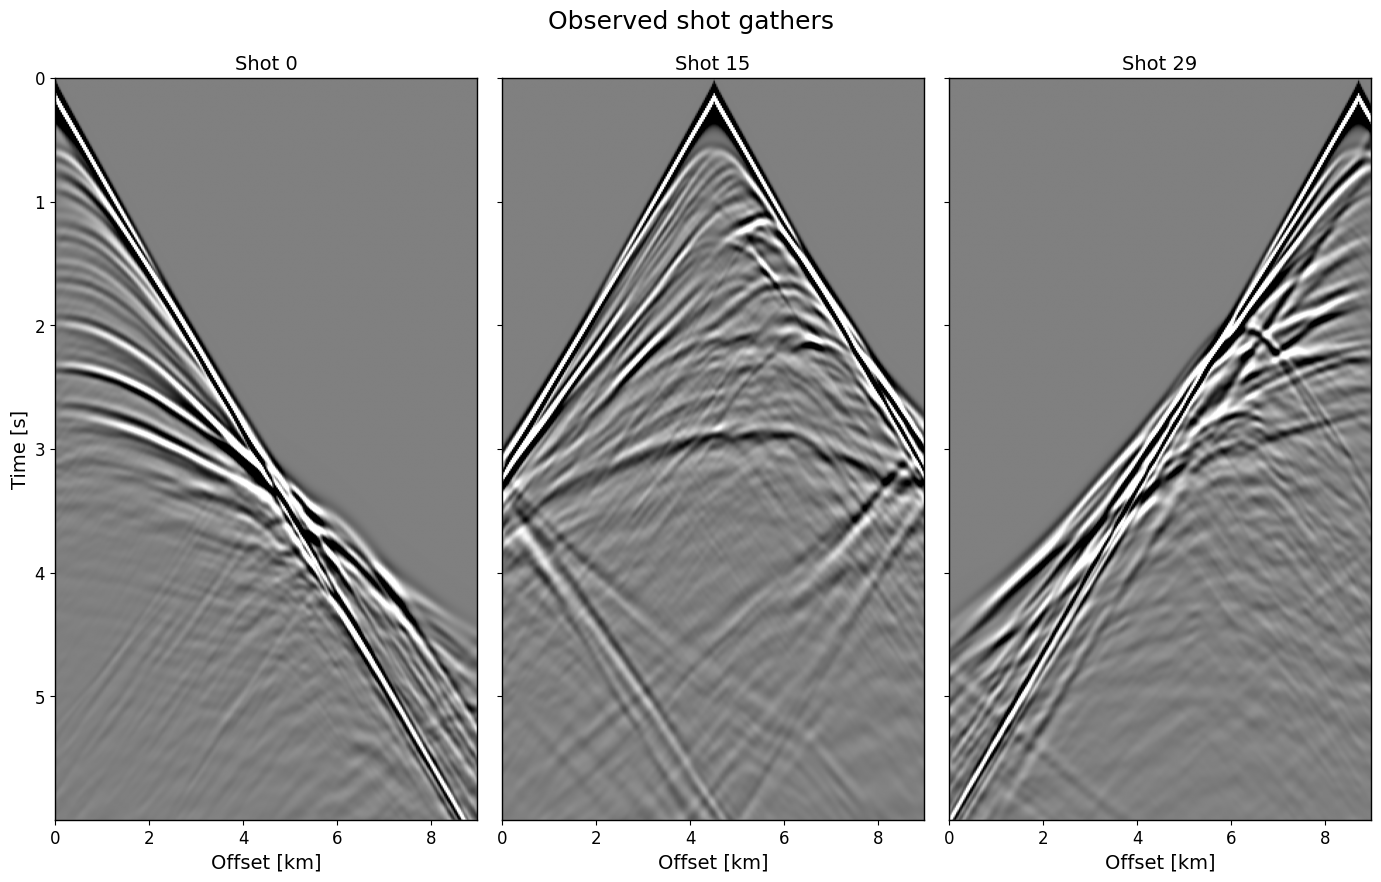

In [11]:
# Plot shot gathers
d_vmin, d_vmax = np.percentile(np.hstack(dobs).ravel(), [2, 98])

plot_shotgathers(lambda i: dobs[i], [0, par['ns']//2, par['ns']-1], x_r, tmax,
                  "Observed shot gathers", vmin=-d_vmax, vmax=d_vmax)

## Mask creation

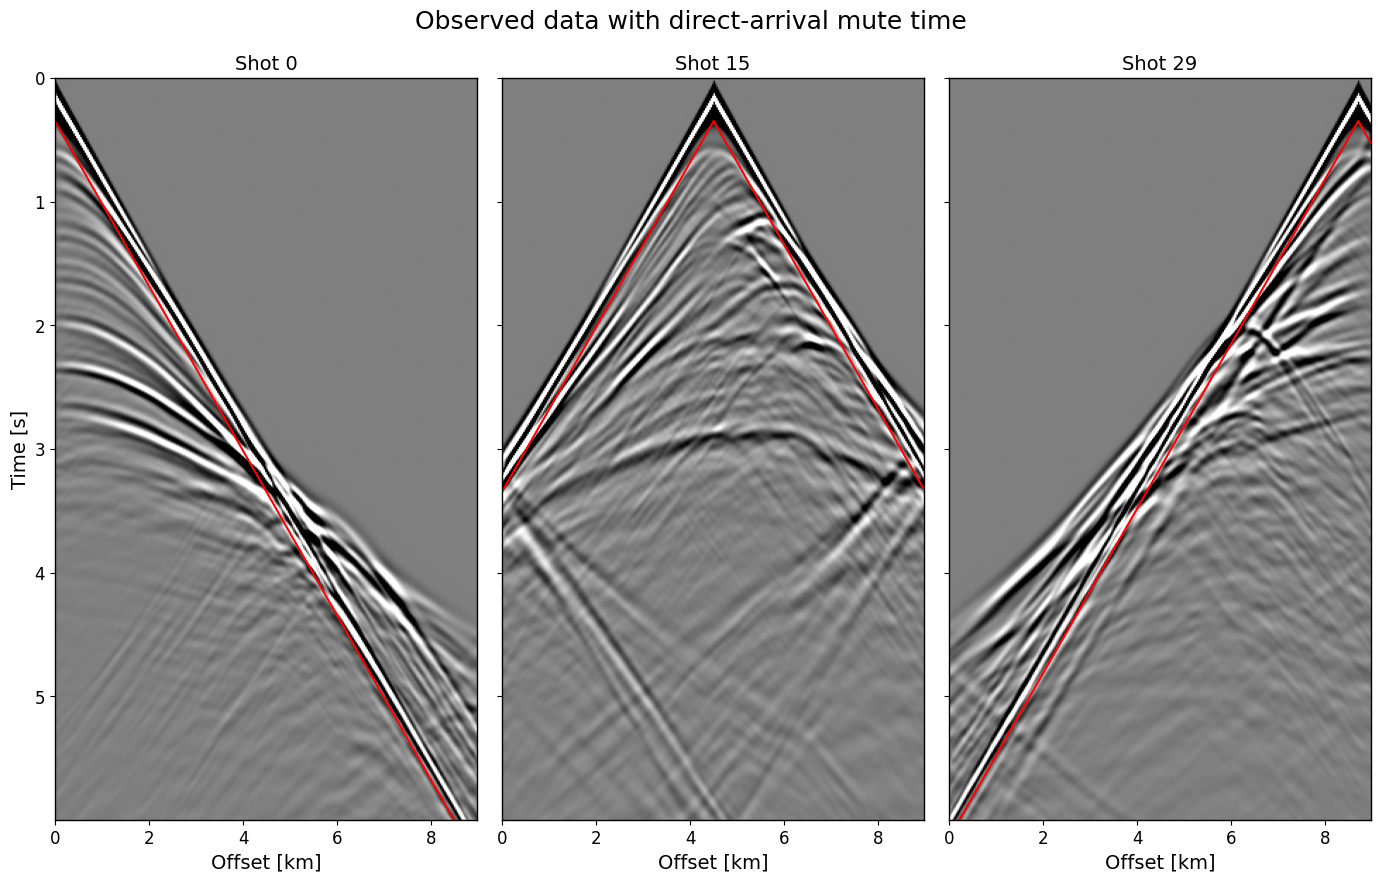

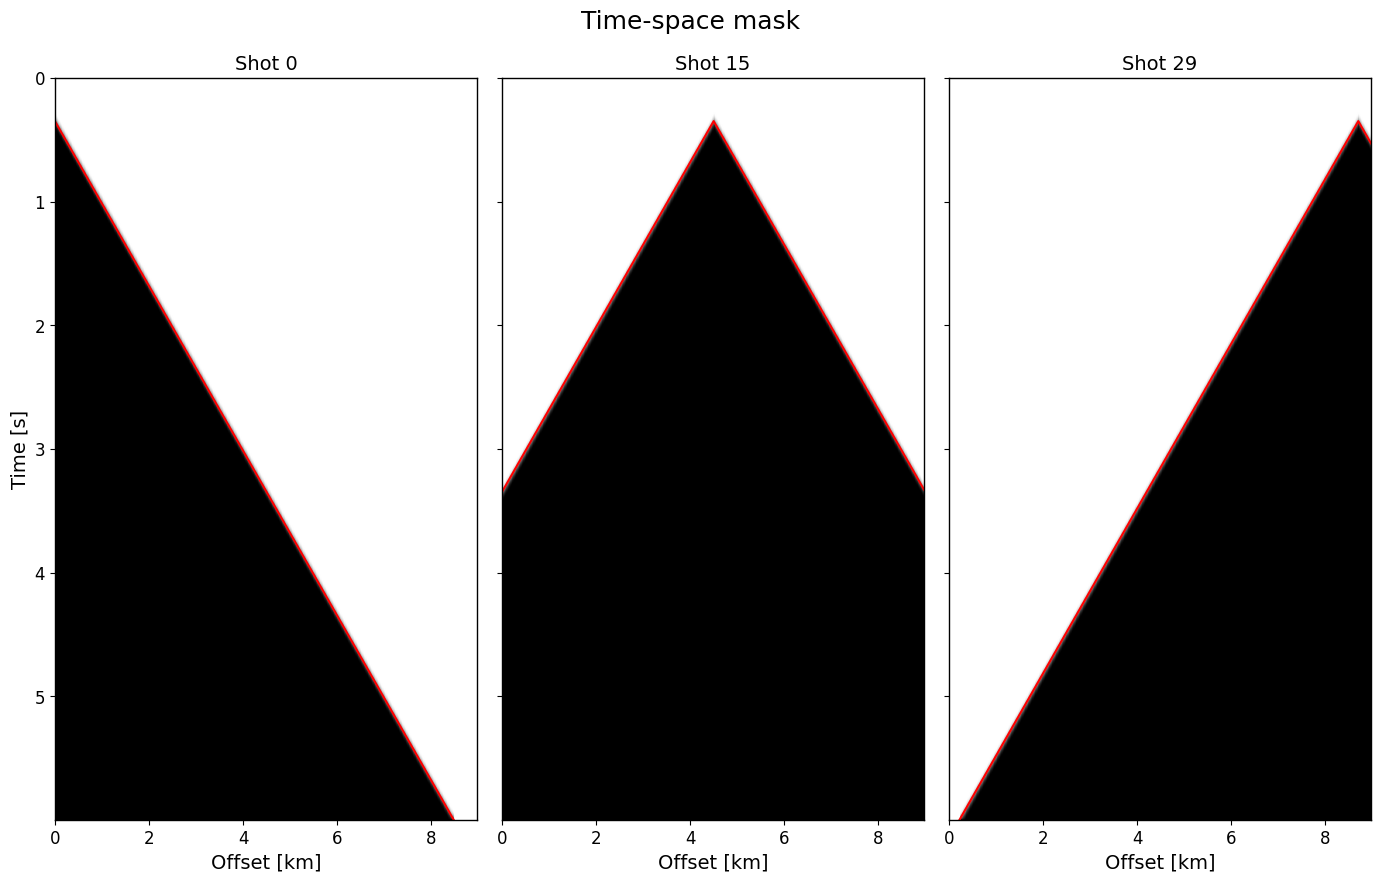

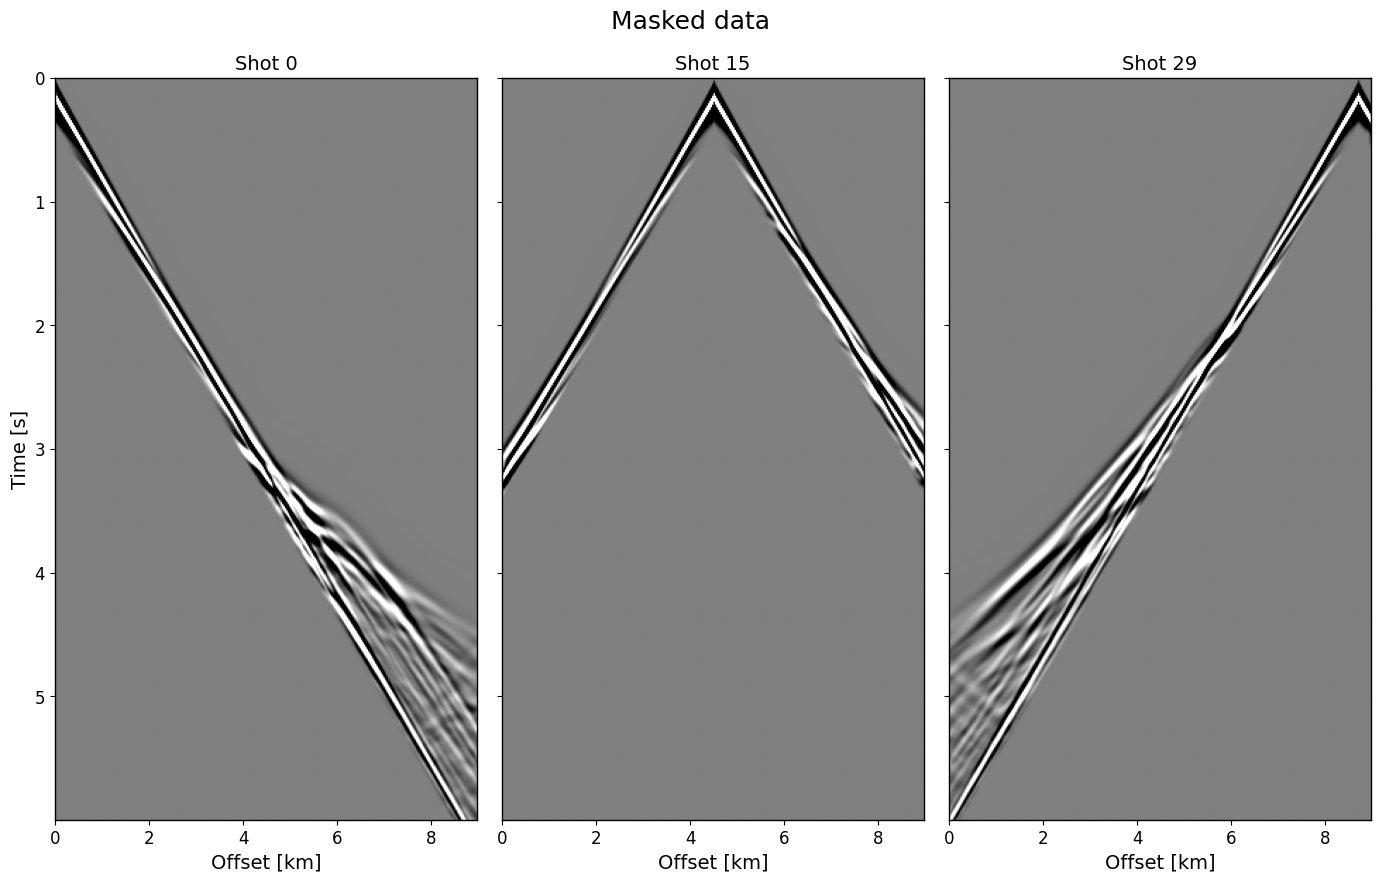

In [12]:
# Create direct arrival mask
distance = np.sqrt((x_s[:, 0][:, None]-x_r[:, 0][None, :])**2 + (x_s[:, 1][:, None]-x_r[:, 1][None, :])**2)
directtime = distance / vwater
tsmask = TimeSpaceMasking(directtime, geometry.nt, geometry.dt, toff, nsmooth=50)

ishots = [0, par['ns']//2, par['ns']-1]

plot_shotgathers(lambda i: dobs[i], ishots, x_r, tmax,
                  "Observed data with direct-arrival mute time",
                  vmin=-d_vmax, vmax=d_vmax,
                  directtime=directtime, toff=toff)

plot_shotgathers(lambda i: tsmask.mask[i].T, ishots, x_r, tmax,
                  "Time-space mask",
                  vmin=0, vmax=1,
                  directtime=directtime, toff=toff)

plot_shotgathers(lambda i: dobs[i] * tsmask.mask[i].T, ishots, x_r, tmax,
                  "Masked data", outpath=f'{exp_name}/data',
                  vmin=-d_vmax, vmax=d_vmax)

## Inversion with L-BFGS

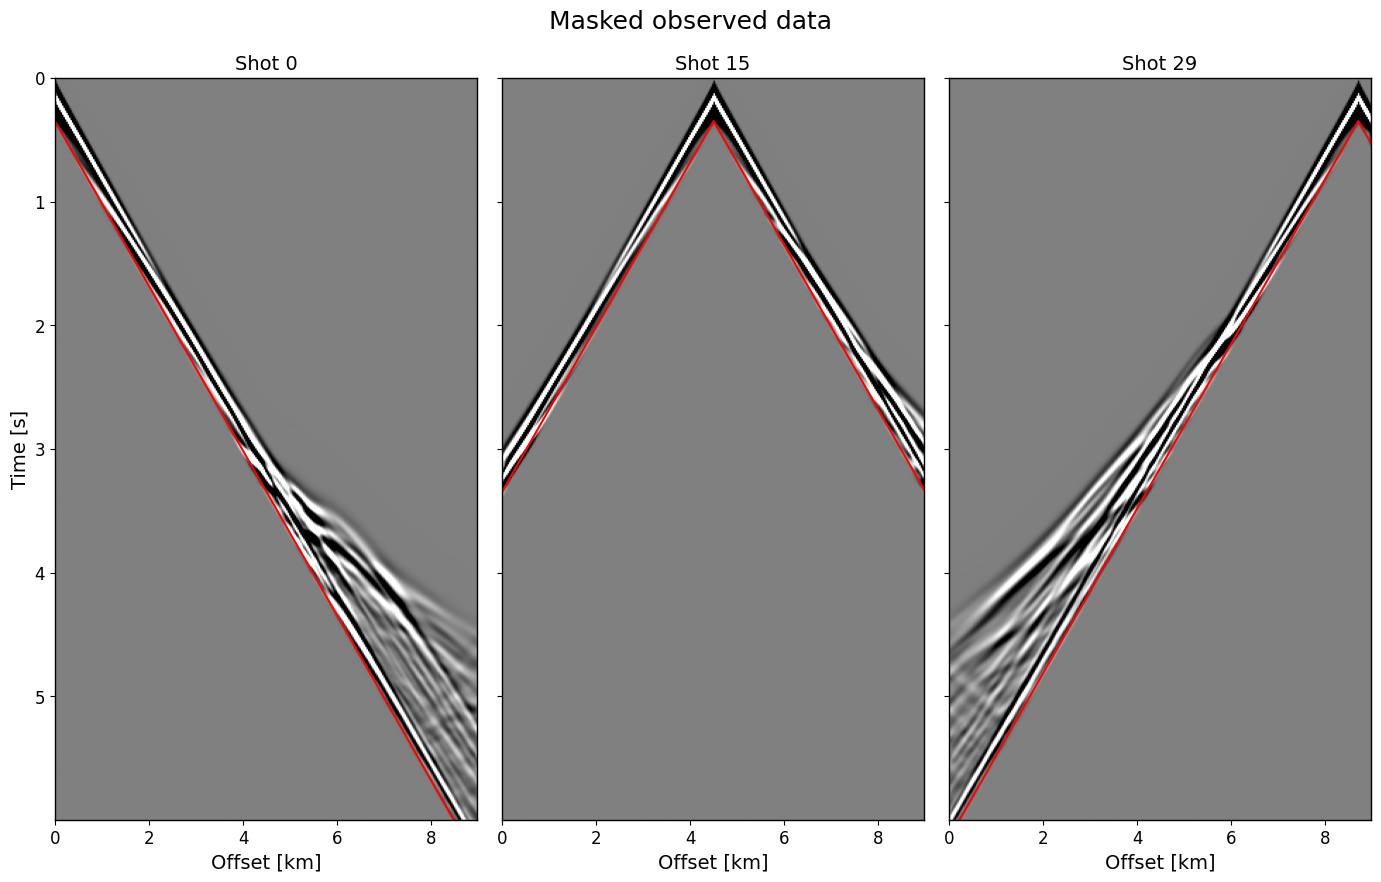

In [13]:
# Mask observed data to have direct arrival and refractions
TSmaskop = [Diagonal(tsmask.mask[isrc].T.ravel()) for isrc in range(par['ns'])]
dobs_masked = np.hstack([(TSmaskop[isrc] @ dobs[isrc].ravel())[None, :] for isrc in range(par['ns'])])
dobs_masked = dobs_masked.reshape(par['ns'], geometry.nt, par['nr'])

plot_shotgathers(lambda i: dobs_masked[i], ishots, x_r, tmax,
                  "Masked observed data",
                  vmin=-d_vmax, vmax=d_vmax,
                  directtime=directtime, toff=toff)

In [ ]:
# Define the loss function
lossfn = lossfn.lower()
l2loss = None
feat_loss = None
if lossfn in ("l2", "hybrid"):
    l2loss = L2(TSmaskop, dobs_masked.reshape(par['ns'], -1))

if lossfn in ("feature", "hybrid"):

    ckpt_path = "../pretrained_seislm_base/checkpoints/epoch=39-step=1203000.ckpt"
    device = "cuda" if torch.cuda.is_available() else "cpu"

    model = load_pretrained_multidim_wav2vec2(ckpt_path, map_location=device)
    model = model.to(device).eval()

    print(type(model))
    feat_loss = SeisLMFeatureLoss(
        seislm_model=model,
        Op=TSmaskop,
        b=dobs_masked.reshape(par['ns'], -1),
        nr=par['nr'],
        nt=geometry.nt,
        t_sub=1,
        device="cuda" if torch.cuda.is_available() else "cpu",
        pool="mean",
        normalize_traces=True,
        trace_chunk=8,
        cache_obs_embeddings=True,
        cache_obs_on_cpu=True,
    )

In [15]:
# Select final loss function
if lossfn == "l2":
    loss_fn = l2loss

elif lossfn == "feature":
    loss_fn = feat_loss

elif lossfn == "hybrid":
    schedule = lambda it: min(1.0, it / 100.0)

    loss_fn = HybridLoss(
        l2_loss=l2loss,
        seislm_loss=feat_loss,
        alpha=schedule
    )

In [16]:
wav = geometry.src.wavelet
ainv = AcousticWave2D(shape, origin, spacing, 
                      x_s[:, 0], x_s[:, 1], x_r[:, 0], x_r[:, 1], 
                      0., tmax,  
                      vprange=(vp_true.min(), vp_true.max()),
                      wav=wav,
                      f0=par['freq'],
                      space_order=space_order, nbl=nbl,
                      loss=loss_fn
                      );

100%|██████████| 30/30 [01:41<00:00,  3.39s/it]


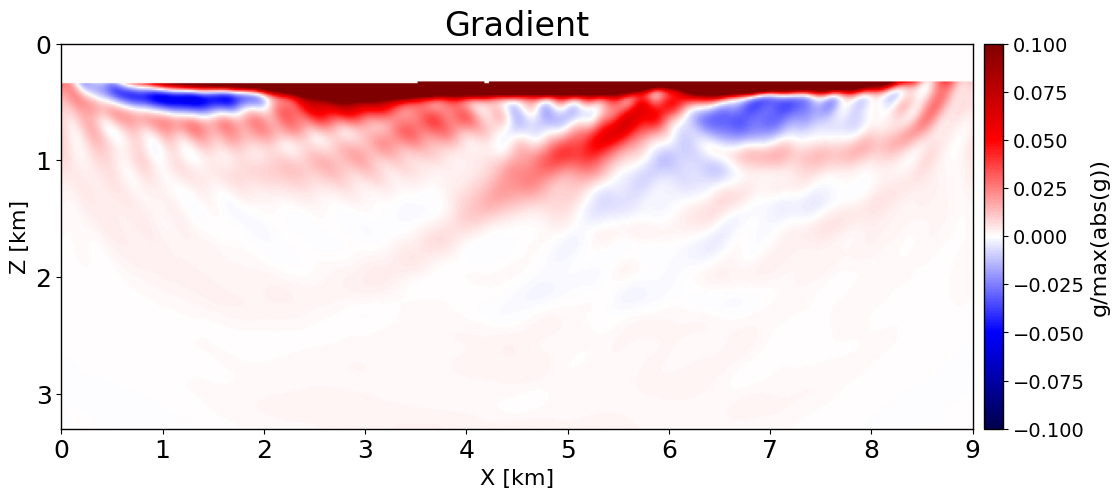

saved test_marmousi_l2_sm_60_40_freq_7Hz/grad.png


In [17]:
# Compute first gradient and find scaling. The water layer has zero gradient.
postproc = PostProcessVP(scaling=1, mask=msk, sigmas=(4, 4))
loss0, direction = ainv._loss_grad(vp_init, postprocess=postproc.apply)
scaling = np.abs(direction).max()

plot_velmodel(direction / scaling, "Gradient", f"{exp_name}/grad.png",
              x, z, cmap="seismic", vmin=-1e-1, vmax=1e-1, clbl="g/max(abs(g))")

np.save(f'{exp_name}/grad.npy', direction)

In [18]:
def fwi_callback(xk, vp, vp_error, misfit_history, lossfn=None):
    misfit_history.append(loss_fn._loss_value)
    vp_error.append(np.linalg.norm((xk - vp.reshape(-1)) / vp.reshape(-1)) / np.sqrt(vp.size))
    it = len(misfit_history)
    extra = ""
    if lossfn == 'hybrid':
        extra = f"  Outer iter {loss_fn._iter}: alpha={loss_fn.alpha:.4f}"
        loss_fn.step()
    print(f"  iter {it:3d}  loss = {misfit_history[-1]:.4e}  err = {vp_error[-1]:.4e}{extra}", flush=True)

In [19]:
# FWI with L-BFGS
ftol = 1e-30
gtol = 1e-30
maxiter = 100
maxfun = 50000
misfit_history = []
convertvp = None
vp_error = [np.linalg.norm((vp_init.reshape(-1) - vp_true.reshape(-1))/vp_true.reshape(-1))/np.sqrt(vp_true.size)]
postproc = PostProcessVP(scaling=scaling, mask=msk, sigmas=(4, 4)).apply

In [ ]:
with open(f"{exp_name}/minimize_log_{lossfn}.txt", "w", buffering=1) as log:
    tee_out = Tee(sys.stdout, log)
    tee_err = Tee(sys.stderr, log)
    with redirect_stdout(tee_out), redirect_stderr(tee_err):
        nl = minimize(
            ainv.loss_grad,
            vp_init.ravel(),
            method="L-BFGS-B",
            jac=True,
            args=(convertvp, postproc),
            callback=lambda x: fwi_callback(
                x,
                vp=vp_true,
                vp_error=vp_error,
                misfit_history=misfit_history,
                lossfn=lossfn,
            ),
            options={
                "ftol": ftol,
                "gtol": gtol,
                "maxiter": maxiter,
                "maxfun": maxfun,
                "disp": True,
            },
        )
        print(nl)

100%|██████████| 30/30 [01:53<00:00,  3.79s/it]


  iter   1  loss = 1.5189e-07  err = 1.3899e-01


100%|██████████| 30/30 [01:47<00:00,  3.58s/it]


  iter   2  loss = 1.5009e-07  err = 1.3895e-01


100%|██████████| 30/30 [01:50<00:00,  3.68s/it]


  iter   3  loss = 1.4232e-07  err = 1.3878e-01


... (37 outputs left out)

  iter  22  loss = 6.5087e-08  err = 1.4666e-01


100%|██████████| 30/30 [02:01<00:00,  4.05s/it]


  iter  23  loss = 6.2317e-08  err = 1.4708e-01


 13%|█▎        | 4/30 [00:19<01:59,  4.61s/it]

In [ ]:
plot_curve(np.array(misfit_history) / misfit_history[0], "Loss", 
           "Normalized loss", f"{exp_name}/loss.png")

plot_curve(ainv.losshistory / ainv.losshistory[0], "Loss history", 
           "Normalized loss", f"{exp_name}/loss_hist.png")

plot_curve(vp_error, "Velocity error", "RMS relative velocity error", 
           f"{exp_name}/err.png",)

np.save(f'{exp_name}/loss.npy', np.array(misfit_history))
np.save(f'{exp_name}/loss_hist.npy', np.array(ainv.losshistory))
np.save(f'{exp_name}/err.npy', np.array(vp_error))

In [ ]:
vp_inv = nl.x.reshape(shape)
plot_velmodel(vp_inv, "Inverted velocity model", f"{exp_name}/vp_inv.png",
              x, z, vmin=vmin, vmax=vmax)
np.save(f'{exp_name}/vp_inv.npy', vp_inv)

In [ ]:
# Inversion with reflection
l2loss = L2(Identity(int(np.prod(dobs.shape[1:]))), dobs.reshape(par['ns'], -1))
loss_fn = l2loss

wav = geometry.src.wavelet
ainv2 = AcousticWave2D(shape, origin, spacing, 
                    x_s[:, 0], x_s[:, 1], x_r[:, 0], x_r[:, 1], 
                    0., tmax,  
                    vprange=(vp_true.min(), vp_true.max()),
                    wav=wav, f0=par['freq'],
                    space_order=space_order, nbl=nbl,
                    loss=l2loss);

In [ ]:
# Compute first gradient and find scaling. The water layer has zero gradient.
postproc = PostProcessVP(scaling=1, mask=msk, sigmas=(4, 4))
loss0, direction = ainv2._loss_grad(vp_inv, postprocess=postproc.apply)
scaling = np.abs(direction).max()

plot_velmodel(direction / scaling, "Gradient - reflections", f"{exp_name}/grad_refl.png",
              x, z, cmap="seismic", vmin=-1e-1, vmax=1e-1, clbl="g/max(abs(g))")
np.save(f'{exp_name}/grad_refl.npy', direction)

In [ ]:
# FWI with L-BFGS
ftol = 1e-30
maxiter = 100
maxfun = 5000
vp_error2 = []
misfit_history2 = []
postproc = PostProcessVP(scaling=scaling, mask=msk, sigmas=(4, 4)).apply

In [ ]:
with open(f"{exp_name}/minimize_log_{lossfn}.txt", "a", buffering=1) as log:
    log.write("\n" + "=" * 80 + "\n")
    log.write("Inversion with reflection starts\n")
    log.write("=" * 80 + "\n\n")

    with redirect_stdout(Tee(sys.stdout, log)), redirect_stderr(Tee(sys.stderr, log)):
        nl2 = minimize(
            ainv2.loss_grad,
            vp_inv.ravel(),
            method="L-BFGS-B",
            jac=True,
            args=(convertvp, postproc),
            callback=lambda x: fwi_callback(
                x,
                vp=vp_true,
                vp_error=vp_error2,
                misfit_history=misfit_history2,
            ),
            options={
                "ftol": ftol,
                "gtol": gtol,
                "maxiter": maxiter,
                "maxfun": maxfun,
                "disp": True,
            },
        )
        print(nl2)

In [ ]:
plot_curve(np.array(misfit_history2) / misfit_history2[0], "Loss", 
           "Normalized loss", f"{exp_name}/loss_refl.png")

plot_curve(ainv2.losshistory / ainv2.losshistory[0], "Loss history", 
           "Normalized loss", f"{exp_name}/loss_hist_refl.png")

plot_curve(vp_error2, "Velocity error", "RMS relative velocity error", 
           f"{exp_name}/err_refl.png",)

np.save(f'{exp_name}/loss_refl.npy', np.array(misfit_history2))
np.save(f'{exp_name}/loss_hist_refl.npy', np.array(ainv2.losshistory))
np.save(f'{exp_name}/err_refl.npy', np.array(vp_error2))

In [ ]:
vp_invr = nl2.x.reshape(shape)

plot_velmodel(vp_invr, "Inverted velocity model - reflections", f"{exp_name}/vp_inv_refl.png",
              x, z, vmin=vmin, vmax=vmax)

np.save(f'{exp_name}/vp_inv_refl.npy', vp_invr)

In [ ]:
plot_curve(np.array(misfit_history) / misfit_history[0], "Loss", 
           "Normalized loss", f"{exp_name}/loss_full.png",
           data2=np.array(misfit_history2) / misfit_history2[0])

plot_curve(ainv.losshistory / ainv.losshistory[0], "Loss history", 
           "Normalized loss", f"{exp_name}/loss_hist_full.png",
           data2=ainv2.losshistory / ainv2.losshistory[0])

plot_curve(vp_error, "Velocity error", "RMS relative velocity error", 
           f"{exp_name}/err_full.png", data2=vp_error)